# 02 · Automated Labeling

**Goal.** Give every post a risk **tier** (0 Neutral · 1 Stress · 2 Moderate · 3 Crisis) **automatically**,
without any human annotators.

**Why it matters.** Hand-labelling thousands of posts is slow and needs experts. Instead we use two
independent automatic labellers and measure how much they agree (Cohen's kappa) as a quality check.

**What happens below.** (1) a curated word-list labeller, (2) a correction step, (3) a language model that
re-labels confident cases, then (4) we compare the two labellers and keep the agreed labels.

**Output:** `data/stage1_labeled/` (every post now has a `tier`).

## 0. Environment & dependencies

Core (`numpy`, `pandas`) always load. Heavier libs are imported **defensively** with availability flags
(same pattern as notebook 01). The MuRIL backbone (`torch` + `transformers`) is used when present; if it is
absent the notebook falls back to a TF-IDF + linear stand-in for Labeler B and **says so in the report**.

In [1]:
import os, re, json, math, unicodedata, hashlib, logging, random, warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

def _try(name):
    try:
        __import__(name); return True
    except Exception:
        return False

HAS_SKLEARN      = _try("sklearn")
HAS_SCIPY        = _try("scipy")
HAS_TORCH        = _try("torch")
HAS_TRANSFORMERS = _try("transformers")
HAS_LANGID       = _try("langid")
HAS_MPL          = _try("matplotlib")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger("label")

log.info("deps -> sklearn=%s scipy=%s torch=%s transformers=%s langid=%s matplotlib=%s",
         HAS_SKLEARN, HAS_SCIPY, HAS_TORCH, HAS_TRANSFORMERS, HAS_LANGID, HAS_MPL)

hinglish-mental-health-detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-08-07 19:15:36,525 | INFO | deps -> sklearn=True scipy=True torch=True transformers=True langid=True matplotlib=True


## 1. Configuration

Paths, the self-training confidence gate **τ = 0.90** (design §6), the MuRIL model id, and the SSL seed
cutoff. Nothing here needs editing for a normal run.

In [2]:
def find_project_root():
    here = Path.cwd().resolve()
    for d in [here, *here.parents]:
        if (d / "data" / "stage1_harvest").exists() or (d / ".env").exists():
            return d
    return here

PROJECT_ROOT = find_project_root()
HARVEST_DIR  = PROJECT_ROOT / "data" / "stage1_harvest"
INPUT_JSONL  = HARVEST_DIR / "stage1_part1_1_harvest.jsonl"
OUTPUT_DIR   = PROJECT_ROOT / "data" / "stage1_labeled"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def find_lexicon():
    cands = [Path.cwd() / "lexicon_mh_v1.json",
             PROJECT_ROOT / "Objective 1" / "lexicon_mh_v1.json"]
    for c in cands:
        if c.exists():
            return c
    hits = list(PROJECT_ROOT.glob("**/lexicon_mh_v1.json"))
    return hits[0] if hits else None

LEXICON_PATH = find_lexicon()

# ---- labeling parameters ----
TAU                = 0.90                       # self-training softmax gate (design §6)
MURIL_MODEL        = "google/muril-base-cased"  # Labeler B backbone
USE_MURIL          = HAS_TORCH and HAS_TRANSFORMERS
SEED_TOP_FRACTION  = 0.60                        # keep the most-confident ~60% of corrected rows as SSL seed
MURIL_EPOCHS       = 3
MURIL_MAXLEN       = 96
MURIL_BATCH        = 16
MURIL_LR           = 2e-5
LANGID_KEEP        = {"en", "hi"}               # langid codes kept (plus Hinglish/Devanagari heuristic)
TIER_NAMES         = {0: "Neutral", 1: "Stress", 2: "Moderate", 3: "Crisis"}
N_LABELS           = 4

log.info("PROJECT_ROOT=%s", PROJECT_ROOT)
log.info("INPUT=%s", INPUT_JSONL)
log.info("LEXICON=%s", LEXICON_PATH)
log.info("tau=%.2f  USE_MURIL=%s (%s)", TAU, USE_MURIL, MURIL_MODEL if USE_MURIL else "stand-in")

2026-08-07 19:15:37,204 | INFO | PROJECT_ROOT=hinglish-mental-health-detection


2026-08-07 19:15:37,205 | INFO | INPUT=hinglish-mental-health-detection\data\stage1_harvest\stage1_part1_1_harvest.jsonl


2026-08-07 19:15:37,206 | INFO | LEXICON=hinglish-mental-health-detection\resources\lexicon_mh_v1.json


2026-08-07 19:15:37,208 | INFO | tau=0.90  USE_MURIL=True (google/muril-base-cased)


## 2. Load corpus

Reads the combined notebook 01 harvest (JSONL = source of truth). Every record already carries the mandatory
schema (`anonymized_user_id`, `timestamp`, `post_text`, `platform`) + 6 temporal features + retained
metadata — all of which flow through unchanged; notebook 02 only **adds** label columns.

In [3]:
def load_corpus(path):
    rows = []
    with open(path, encoding="utf-8") as fh:
        for line in fh:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    df = pd.DataFrame(rows)
    log.info("Loaded %d records (%s)", len(df), path.name)
    return df

df_raw = load_corpus(INPUT_JSONL)
print("platforms:", dict(df_raw["platform"].value_counts()))
df_raw.head(2)

2026-08-07 19:15:37,323 | INFO | Loaded 5213 records (stage1_part1_1_harvest.jsonl)


platforms: {'youtube': np.int64(2200), 'twitter': np.int64(1573), 'reddit': np.int64(1440)}


platform anonymized_user_id                  timestamp  \
0  youtube   13c44953989c1ec2  2021-12-30T21:32:26+00:00   
1  youtube   415216e8be27144e  2026-06-22T14:44:18+00:00   

                                           post_text      source_ref  \
[real post text redacted]
[real post text redacted]

                              record_id     month       day      hour  \
0  89e8a9cd-bcfe-4de8-9b8f-482adf84ac67  1.000000  0.966667  0.913043   
1  49277a07-0941-4f6d-8320-59b0ff46274f  0.454545  0.700000  0.608696   

   weekday  is_working_hour  is_weekend  post_length_chars  \
0      0.5              0.0         0.0                552   
1      0.0              1.0         0.0                167   

   post_length_tokens  score  reply_count  share_count parent_id  \
0                  84    208         61.0          NaN      None   
1                  32      0          0.0          NaN      None   

                                       raw_meta_json  
0  {"channelId": "UCSlTJnomY7jbqSdpaP3NKjA", "vid...  
1  {"channelId": "UCSlTJnomY7jbqSdpaP3NKjA", "vid...

## 3. Step 0 — clean + language identification

notebook 01 was deliberately permissive. Here we NFC-normalise, strip URLs/whitespace, drop near-empty text,
and **language-ID** to keep Hinglish / Hindi / English and drop clearly off-language rows — this is where
the known **Twitter Tagalog** false matches (`hindi` = *"not"* in Filipino) are removed *before* any tier
is assigned. Detection order: Devanagari → keep; romanized-Hindi function-word markers → keep (Hinglish);
otherwise `langid` decides (Tagalog `tl`, etc. → drop). Filtering here is reversible and logged.

In [4]:
URL_RE        = re.compile(r"https?://\S+|www\.\S+")
WS_RE         = re.compile(r"\s+")
DEVANAGARI_RE = re.compile(r"[ऀ-ॿ]")

# romanized-Hindi function words: strong, cheap signal that a Latin-script post is Hinglish/Hindi
HINGLISH_MARKERS = {
    "hai","hain","tha","thi","nahi","nhi","nahin","kya","kyu","kyun","kyon","mera","meri","mere",
    "mujhe","muje","tum","tumhe","tera","teri","kuch","kuchh","bahut","bohot","bhot","yaar","yar",
    "bhai","behen","acha","accha","achha","theek","thik","kaise","kaisa","kaisi","raha","rahi","rahe",
    "hona","karna","karo","kar","ho","hu","hoon","ka","ki","ke","ko","se","mein","par","aur","ya",
    "matlab","sab","sabko","apna","apne","apni","log","logo","baat","din","raat","zindagi","jindagi",
    "mann","man","dil","bas","abhi","kal","aaj","kyunki","lekin","magar","phir","fir","wala","wali",
}

def clean_text(t):
    t = unicodedata.normalize("NFC", str(t or ""))
    t = URL_RE.sub(" ", t)
    t = t.replace("​", " ").replace("﻿", " ")
    t = WS_RE.sub(" ", t).strip()
    return t

def detect_lang(t):
    # -> (label, keep_bool). keep = Hinglish / Hindi / English target band.
    if DEVANAGARI_RE.search(t):
        return "hi", True
    toks = re.findall(r"[a-zA-Z']+", t.lower())
    if not toks:
        return "und", False
    if sum(1 for w in toks if w in HINGLISH_MARKERS) >= 1:
        return "hinglish", True
    if HAS_LANGID:
        import langid
        code, _ = langid.classify(t)
        return code, (code in LANGID_KEEP)
    # no langid available: keep latin-script text (English-ish) rather than over-drop
    return "en?", True

df = df_raw.copy()
df["post_text_clean"] = df["post_text"].map(clean_text)
df = df[df["post_text_clean"].str.len() >= 3].copy()

_lang = df["post_text_clean"].map(detect_lang)
df["lang"]      = [a for a, _ in _lang]
df["lang_keep"] = [b for _, b in _lang]

df_lang = df[df["lang_keep"]].reset_index(drop=True)
log.info("Step 0: %d raw -> %d kept (dropped %d empty/off-language)",
         len(df_raw), len(df_lang), len(df_raw) - len(df_lang))
print("language tags kept:\n", df_lang["lang"].value_counts())
print("\nper-platform kept:\n", df_lang["platform"].value_counts())

2026-08-07 19:15:37,401 | INFO | initializing identifier


2026-08-07 19:15:51,464 | INFO | Step 0: 5213 raw -> 4614 kept (dropped 599 empty/off-language)


language tags kept:
 lang
en          3120
hinglish    1392
hi           102
Name: count, dtype: int64

per-platform kept:
 platform
youtube    1846
twitter    1466
reddit     1302
Name: count, dtype: int64


## 4. Lexicon module (versioned, auditable)

The Tier 1–3 token sets and the topical/sarcasm **demote** list are loaded from `lexicon_mh_v1.json`
(seeded from Garg 2023 / Alakananda 2025 + methodology anchor terms). ASCII single words match on word
boundaries; phrases and Devanagari match as normalized substrings.

In [5]:
def load_lexicon(path):
    lex = json.loads(Path(path).read_text(encoding="utf-8"))
    compiled = []
    for tier_str, blk in lex["tiers"].items():
        tier = int(tier_str)
        for term in blk["terms"]:
            term_n = unicodedata.normalize("NFC", term.lower())
            if re.search(r"[a-z]", term_n) and " " not in term_n:
                pat = re.compile(r"\b" + re.escape(term_n) + r"\b")
            else:
                pat = re.compile(re.escape(term_n))
            compiled.append((tier, term_n, pat))
    demote = [unicodedata.normalize("NFC", d.lower()) for d in lex.get("topical_demote", [])]
    return lex, compiled, demote

LEXICON, LEX_COMPILED, LEX_DEMOTE = load_lexicon(LEXICON_PATH)
log.info("Lexicon v%s: %d terms (tiers 1-3), %d demote phrases",
         LEXICON["version"], len(LEX_COMPILED), len(LEX_DEMOTE))

2026-08-07 19:15:51,490 | INFO | Lexicon v1.0: 142 terms (tiers 1-3), 31 demote phrases


## 5. Step 1 — Lexicon weak labels (Labeler A)

Membership rules assign a provisional Tier 0–3 to every post (Alakananda 2025's pre-labeling stage **with
its human review removed**). The **highest** matched tier wins (escalation). A post hitting the topical/
sarcasm **demote** list (news, lyrics, "the great depression", …) is demoted one tier — **except Crisis
(Tier 3), which is never auto-demoted** (safety). This is **Labeler A** for the κ statistic.

In [6]:
def weak_label(text):
    t = unicodedata.normalize("NFC", str(text).lower())
    is_topical = any(d in t for d in LEX_DEMOTE)
    matched = defaultdict(set)
    for tier, term, pat in LEX_COMPILED:
        if pat.search(t):
            matched[tier].add(term)
    if not matched:
        return {"tier": 0, "conf": 0.50, "hits": [], "topical": is_topical}
    top  = max(matched)
    hits = sorted(matched[top])
    conf = min(0.95, 0.55 + 0.13 * len(hits))
    if is_topical and top < 3:                 # demote non-personal mentions (never Crisis)
        top = max(0, top - 1); conf *= 0.70
    return {"tier": top, "conf": round(conf, 3), "hits": hits, "topical": is_topical}

_wl = df_lang["post_text_clean"].map(weak_label)
df_lang["tier_lexicon"] = [w["tier"] for w in _wl]
df_lang["lex_conf"]     = [w["conf"] for w in _wl]
df_lang["lex_hits"]     = [w["hits"] for w in _wl]
df_lang["lex_topical"]  = [w["topical"] for w in _wl]

print("Labeler A (lexicon) tier distribution:")
print(df_lang["tier_lexicon"].value_counts().sort_index().rename(index=TIER_NAMES))
log.info("topical/sarcasm demotions flagged: %d", int(df_lang["lex_topical"].sum()))

2026-08-07 19:15:52,876 | INFO | topical/sarcasm demotions flagged: 154


Labeler A (lexicon) tier distribution:
tier_lexicon
Neutral     3132
Stress       565
Moderate     856
Crisis        61
Name: count, dtype: int64


## 6. Step 2 — SDCNL-style automated label correction

The weak labels are treated as **noisy**. We learn from them with a character-n-gram TF-IDF + logistic
regression, obtain **out-of-fold** predictions (so a row never sees itself in training), and **flip** a
label only where the model is *confidently and consistently* against it (pred prob ≥ 0.80 **and** the
weak label's own predicted prob < 0.30). Rare **Crisis (Tier 3)** labels are protected from being flipped
away unless the model is overwhelmingly confident (≥ 0.95) — guarding the class the augmentation suite
(notebook 03) depends on. No human review; SDCNL is the published automated remedy (Garg 2023).

In [7]:
def sdcnl_correct(texts, weak, flip_thr=0.80, weak_lo=0.30):
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedKFold

    texts = list(texts); y = np.asarray(weak, dtype=int)
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, max_features=50000)
    X = vec.fit_transform(texts)

    oof = np.zeros((len(y), N_LABELS))
    counts = np.bincount(y, minlength=N_LABELS)
    nz = counts[counts > 0]
    if len(nz) > 1 and nz.min() >= 2:
        n_splits = int(min(5, nz.min()))
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
        for tr, va in skf.split(X, y):
            clf = LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0)
            clf.fit(X[tr], y[tr])
            p = clf.predict_proba(X[va])
            for j, c in enumerate(clf.classes_):
                oof[va, c] = p[:, j]
        log.info("SDCNL: %d-fold out-of-fold predictions", n_splits)
    else:
        clf = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X, y)
        p = clf.predict_proba(X)
        for j, c in enumerate(clf.classes_):
            oof[:, c] = p[:, j]
        log.warning("SDCNL: a class has <2 members -> in-sample fallback (optimistic; pilot corpus).")

    pred      = oof.argmax(1)
    pred_conf = oof.max(1)
    weak_conf = oof[np.arange(len(y)), y]
    flip = (pred != y) & (pred_conf >= flip_thr) & (weak_conf < weak_lo)
    protect = (y == 3) & (pred_conf < 0.95)        # don't flip away Crisis cheaply
    flip = flip & ~protect
    corrected = y.copy(); corrected[flip] = pred[flip]
    return corrected, np.round(pred_conf, 4), flip, vec

corrected, corr_conf, flips, VEC = sdcnl_correct(df_lang["post_text_clean"], df_lang["tier_lexicon"])
df_lang["tier_corrected"] = corrected
df_lang["corr_conf"]      = corr_conf
log.info("SDCNL flipped %d / %d labels (%.1f%%)", int(flips.sum()), len(df_lang), 100 * flips.mean())
print("lexicon (rows) -> corrected (cols):")
print(pd.crosstab(df_lang["tier_lexicon"], df_lang["tier_corrected"]))

2026-08-07 19:16:03,395 | INFO | SDCNL: 5-fold out-of-fold predictions


2026-08-07 19:16:03,401 | INFO | SDCNL flipped 22 / 4614 labels (0.5%)


lexicon (rows) -> corrected (cols):
tier_corrected     0    1    2   3
tier_lexicon                      
0               3120   11    0   1
1                  5  560    0   0
2                  1    4  851   0
3                  0    0    0  61


## 7. Step 3 — Confidence-τ self-training with MuRIL (Labeler B)

The **highest-confidence corrected subset** becomes the seed (this *replaces* a manually-labeled seed —
P1). We fine-tune **MuRIL** on it, then predict every row; a row is **auto-accepted** only when softmax
confidence ≥ **τ = 0.90**. The model's per-row prediction is **Labeler B** for the κ statistic. The final
`tier` = the model label where accepted, else the corrected label. If `torch`/`transformers` are absent,
a TF-IDF + logistic-regression stand-in is used and flagged in the report (architecture identical:
fine-tuned classifier → softmax → τ gate).

In [8]:
def _seed_indices(corr_conf, corrected, top_fraction):
    cutoff = float(np.quantile(corr_conf, 1.0 - top_fraction))
    cutoff = max(0.50, cutoff)
    idx = np.where(corr_conf >= cutoff)[0]
    # ensure >=2 classes in the seed; if not, fall back to all rows
    if len(np.unique(corrected[idx])) < 2:
        log.warning("SSL seed had <2 classes at cutoff %.3f -> using all rows as seed.", cutoff)
        idx = np.arange(len(corrected)); cutoff = 0.0
    return idx, cutoff

def train_muril(texts, seed_idx, seed_labels, all_texts):
    import torch
    from torch.utils.data import DataLoader, TensorDataset
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    device = "cuda" if torch.cuda.is_available() else "cpu"
    log.info("MuRIL device=%s; downloading/loading %s ...", device, MURIL_MODEL)
    tok = AutoTokenizer.from_pretrained(MURIL_MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(MURIL_MODEL, num_labels=N_LABELS).to(device)

    def enc(txts):
        e = tok(list(txts), truncation=True, padding="max_length",
                max_length=MURIL_MAXLEN, return_tensors="pt")
        return e["input_ids"], e["attention_mask"]

    Xi, Xm = enc([texts[i] for i in seed_idx])
    yt = torch.tensor(seed_labels, dtype=torch.long)
    dl = DataLoader(TensorDataset(Xi, Xm, yt), batch_size=MURIL_BATCH, shuffle=True)

    counts = np.bincount(seed_labels, minlength=N_LABELS).astype(float)
    cw = torch.tensor(counts.sum() / (np.maximum(counts, 1) * N_LABELS), dtype=torch.float).to(device)
    lossf = torch.nn.CrossEntropyLoss(weight=cw)
    opt = torch.optim.AdamW(model.parameters(), lr=MURIL_LR)

    model.train()
    for ep in range(MURIL_EPOCHS):
        tot = 0.0
        for bi, bm, by in dl:
            bi, bm, by = bi.to(device), bm.to(device), by.to(device)
            opt.zero_grad()
            logits = model(input_ids=bi, attention_mask=bm).logits
            loss = lossf(logits, by); loss.backward(); opt.step(); tot += loss.item()
        log.info("MuRIL epoch %d/%d  loss=%.4f", ep + 1, MURIL_EPOCHS, tot / max(1, len(dl)))

    model.eval()
    Ai, Am = enc(all_texts)
    out = []
    with torch.no_grad():
        for s in range(0, len(all_texts), MURIL_BATCH):
            logits = model(input_ids=Ai[s:s+MURIL_BATCH].to(device),
                           attention_mask=Am[s:s+MURIL_BATCH].to(device)).logits
            out.append(torch.softmax(logits, 1).cpu().numpy())
    return np.vstack(out)

def train_standin(texts, seed_idx, seed_labels, all_texts):
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    v = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2)
    clf = LogisticRegression(max_iter=1000, class_weight="balanced")
    clf.fit(v.fit_transform([texts[i] for i in seed_idx]), seed_labels)
    p = clf.predict_proba(v.transform(all_texts))
    full = np.zeros((len(all_texts), N_LABELS))
    for j, c in enumerate(clf.classes_):
        full[:, c] = p[:, j]
    return full

texts_all  = df_lang["post_text_clean"].tolist()
corr_vals  = df_lang["tier_corrected"].values
seed_idx, seed_cut = _seed_indices(df_lang["corr_conf"].values, corr_vals, SEED_TOP_FRACTION)
seed_labels = corr_vals[seed_idx].astype(int)
log.info("SSL seed: %d / %d rows (corr_conf >= %.3f); classes=%s",
         len(seed_idx), len(texts_all), seed_cut, dict(Counter(seed_labels)))

if USE_MURIL:
    try:
        PROBS = train_muril(texts_all, seed_idx, seed_labels, texts_all); BACKBONE = "google/muril-base-cased"
    except Exception as e:
        log.warning("MuRIL failed (%s) -> stand-in backbone.", e)
        PROBS = train_standin(texts_all, seed_idx, seed_labels, texts_all); BACKBONE = "tfidf-logreg-standin"
else:
    log.warning("torch/transformers absent -> TF-IDF+LogReg stand-in (report flags this).")
    PROBS = train_standin(texts_all, seed_idx, seed_labels, texts_all); BACKBONE = "tfidf-logreg-standin"

tier_model = PROBS.argmax(1)
model_conf = PROBS.max(1)
accept     = model_conf >= TAU
df_lang["tier_model"]  = tier_model
df_lang["model_conf"]  = np.round(model_conf, 4)
df_lang["model_accept"] = accept

final = corr_vals.copy(); final[accept] = tier_model[accept]
df_lang["tier"] = final
df_lang["tier_source"] = np.where(
    accept, "model",
    np.where(df_lang["tier_corrected"].values != df_lang["tier_lexicon"].values, "corrected", "lexicon"))
df_lang["tier_confidence"] = np.round(
    np.where(accept, df_lang["model_conf"].values, df_lang["corr_conf"].values), 4)

log.info("Self-training backbone=%s: %d/%d auto-accepted at tau=%.2f (%.1f%%)",
         BACKBONE, int(accept.sum()), len(df_lang), TAU, 100 * accept.mean())
print("Labeler B (model) tier distribution:")
print(pd.Series(tier_model).value_counts().sort_index().rename(index=TIER_NAMES))
print("\ntier_source:", dict(df_lang["tier_source"].value_counts()))

2026-08-07 19:16:03,444 | INFO | SSL seed: 2768 / 4614 rows (corr_conf >= 0.746); classes={np.int64(0): 1831, np.int64(1): 425, np.int64(2): 493, np.int64(3): 19}


2026-08-07 19:16:06,101 | INFO | MuRIL device=cpu; downloading/loading google/muril-base-cased ...


2026-08-07 19:16:06,383 | INFO | HTTP Request: HEAD https://huggingface.co/google/muril-base-cased/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"


2026-08-07 19:16:06,394 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/google/muril-base-cased/afd9f36c7923d54e97903922ff1b260d091d202f/config.json "HTTP/1.1 200 OK"


2026-08-07 19:16:06,659 | INFO | HTTP Request: HEAD https://huggingface.co/google/muril-base-cased/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"


2026-08-07 19:16:06,668 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/google/muril-base-cased/afd9f36c7923d54e97903922ff1b260d091d202f/tokenizer_config.json "HTTP/1.1 200 OK"


... (17 outputs left out)

2026-08-07 20:31:39,330 | INFO | MuRIL epoch 2/3  loss=0.9336


2026-08-07 21:09:58,231 | INFO | MuRIL epoch 3/3  loss=0.5514


2026-08-07 21:25:12,331 | INFO | Self-training backbone=google/muril-base-cased: 0/4614 auto-accepted at tau=0.90 (0.0%)


Labeler B (model) tier distribution:
Neutral     3145
Stress       532
Moderate     937
Name: count, dtype: int64

tier_source: {'lexicon': np.int64(4592), 'corrected': np.int64(22)}


## 8. Step 4 — Label quality **without humans**

We report **Cohen's κ between the two automated labelers** — lexicon (A) vs model (B) — in place of human
inter-annotator agreement. As a feasibility fallback (design §7), we also compute **class
separability** (silhouette over a TruncatedSVD projection of the TF-IDF space) on the final tiers. If κ
is too low to be meaningful (< 0.20), the report **discloses** that Gold/Silver collapses toward a single
weak-label corpus.

In [9]:
from sklearn.metrics import cohen_kappa_score, silhouette_score
from sklearn.decomposition import TruncatedSVD

def kappa_label(k):
    if k < 0:    return "poor"
    if k < 0.20: return "slight"
    if k < 0.40: return "fair"
    if k < 0.60: return "moderate"
    if k < 0.80: return "substantial"
    return "almost perfect"

a = df_lang["tier_lexicon"].values
b = df_lang["tier_model"].values
KAPPA = float(cohen_kappa_score(a, b))
AGREE_PCT = float((a == b).mean() * 100)
log.info("Inter-labeler Cohen's kappa (A=lexicon vs B=model) = %.4f (%s); raw agreement %.1f%%",
         KAPPA, kappa_label(KAPPA), AGREE_PCT)

SIL = float("nan")
try:
    Xtf = VEC.transform(df_lang["post_text_clean"])
    ncomp = int(min(50, Xtf.shape[1] - 1, Xtf.shape[0] - 1))
    if ncomp >= 2 and df_lang["tier"].nunique() > 1:
        Z = TruncatedSVD(n_components=ncomp, random_state=SEED).fit_transform(Xtf)
        SIL = float(silhouette_score(Z, df_lang["tier"].values))
        log.info("Class separability (silhouette over SVD-%d) = %.4f", ncomp, SIL)
except Exception as e:
    log.warning("silhouette skipped: %s", e)

FALLBACK = KAPPA < 0.20
if FALLBACK:
    log.warning("kappa < 0.20 -> label-quality FALLBACK: reporting separability + correction confidence; "
                "Gold/Silver collapses toward a single weak-label corpus (disclosed).")

2026-08-07 21:25:12,701 | INFO | Inter-labeler Cohen's kappa (A=lexicon vs B=model) = 0.8179 (almost perfect); raw agreement 91.2%


2026-08-07 21:25:17,138 | INFO | Class separability (silhouette over SVD-50) = -0.0117


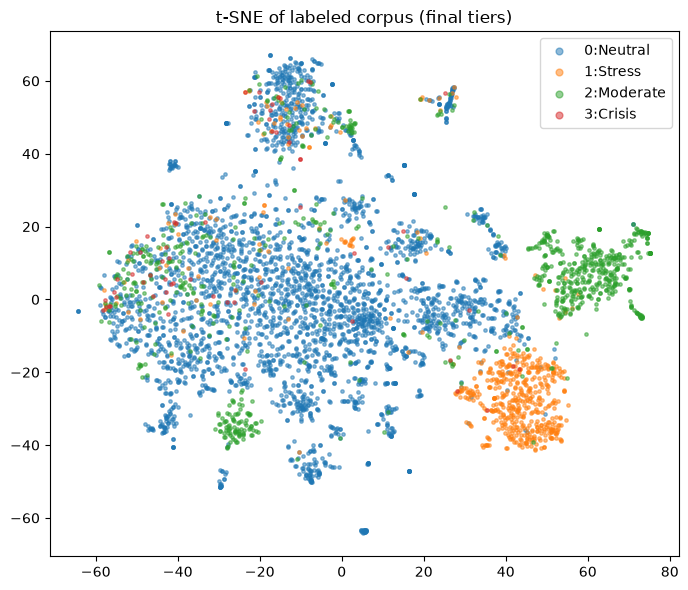

In [10]:
# Optional 2-D t-SNE picture of the labeled space (skips cleanly if matplotlib/scipy absent).
if HAS_MPL and df_lang["tier"].nunique() > 1:
    try:
        import matplotlib.pyplot as plt
        from sklearn.manifold import TSNE
        Xtf = VEC.transform(df_lang["post_text_clean"])
        ncomp = int(min(50, Xtf.shape[1] - 1, Xtf.shape[0] - 1))
        Z = TruncatedSVD(n_components=ncomp, random_state=SEED).fit_transform(Xtf)
        emb = TSNE(n_components=2, init="pca", random_state=SEED,
                   perplexity=min(30, max(5, len(Z)//50))).fit_transform(Z)
        plt.figure(figsize=(7, 6))
        for t in sorted(df_lang["tier"].unique()):
            m = df_lang["tier"].values == t
            plt.scatter(emb[m, 0], emb[m, 1], s=6, alpha=0.5, label=f"{t}:{TIER_NAMES[t]}")
        plt.legend(markerscale=2); plt.title("t-SNE of labeled corpus (final tiers)")
        plt.tight_layout(); plt.show()
    except Exception as e:
        print("t-SNE plot skipped:", e)
else:
    print("t-SNE skipped (matplotlib missing or single class).")

## 9. Step 5 — Gold / Silver split & persistence

**Gold** = both labelers agree **and** model confidence ≥ τ; **Silver** = the rest (design §1/§D4). We
write `labeled_corpus.{jsonl,parquet}` (original schema + new label columns) and a machine-readable
`label_quality_report.json`. Honest naming: if the κ fallback fired, the report records that Gold/Silver
collapses toward a single weak-label corpus.

In [11]:
agree = (df_lang["tier_lexicon"].values == df_lang["tier_model"].values)
gold  = agree & (df_lang["model_conf"].values >= TAU)
df_lang["split"] = np.where(gold, "gold", "silver")

# ---- persist labeled corpus (jsonl source-of-truth + parquet) ----
def dist(series):
    return {int(k): int(v) for k, v in series.value_counts().sort_index().items()}

out_cols = [c for c in df_lang.columns if c != "lang_keep"]
labeled = df_lang[out_cols].copy()

jsonl_path = OUTPUT_DIR / "labeled_corpus.jsonl"
with open(jsonl_path, "w", encoding="utf-8") as fh:
    for _, row in labeled.iterrows():
        fh.write(json.dumps(row.to_dict(), ensure_ascii=False, default=str) + "\n")
log.info("Wrote %s (%d rows)", jsonl_path, len(labeled))
try:
    labeled.to_parquet(OUTPUT_DIR / "labeled_corpus.parquet", index=False)
    log.info("Wrote %s", OUTPUT_DIR / "labeled_corpus.parquet")
except Exception as e:
    log.warning("Parquet skipped (%s). JSONL is the source of truth.", e)

# ---- label-quality report ----
per_platform = {}
for plat, g in df_lang.groupby("platform"):
    per_platform[plat] = {"records": int(len(g)),
                          "gold": int((g["split"] == "gold").sum()),
                          "tier_final": dist(g["tier"])}

report = {
    "part": "stage1_part1.2_automated_labeling",
    "principle": "P1 (fully automatic)",
    "lexicon_version": LEXICON["version"],
    "tau": TAU,
    "backbone": BACKBONE,
    "input_records": int(len(df_raw)),
    "after_language_filter": int(len(df_lang)),
    "dropped_offlanguage_or_empty": int(len(df_raw) - len(df_lang)),
    "ssl_seed_size": int(len(seed_idx)),
    "ssl_seed_conf_cutoff": round(float(seed_cut), 3),
    "sdcnl_flips": int(flips.sum()),
    "auto_accepted": int(accept.sum()),
    "auto_accepted_pct": round(float(accept.mean() * 100), 2),
    "inter_labeler_cohen_kappa": round(KAPPA, 4),
    "kappa_interpretation": kappa_label(KAPPA),
    "label_agreement_pct": round(AGREE_PCT, 2),
    "class_separability_silhouette": (None if math.isnan(SIL) else round(SIL, 4)),
    "label_quality_fallback_triggered": bool(FALLBACK),
    "tier_distribution_lexiconA": dist(df_lang["tier_lexicon"]),
    "tier_distribution_modelB":  dist(pd.Series(df_lang["tier_model"])),
    "tier_distribution_final":   dist(df_lang["tier"]),
    "tier_source_counts": {k: int(v) for k, v in df_lang["tier_source"].value_counts().items()},
    "gold_count": int(gold.sum()),
    "silver_count": int((~gold).sum()),
    "per_platform": per_platform,
    "notes": ("Gold/Silver collapses toward a single weak-label corpus (kappa < 0.20)."
              if FALLBACK else "Gold = labeler agreement AND model_conf >= tau."),
}
report_path = OUTPUT_DIR / "label_quality_report.json"
report_path.write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8")
log.info("Wrote %s", report_path)
print(json.dumps(report, indent=2, ensure_ascii=False))

2026-08-07 21:26:02,485 | INFO | Wrote hinglish-mental-health-detection\data\stage1_labeled\labeled_corpus.jsonl (4614 rows)


2026-08-07 21:26:02,895 | WARNING | Parquet skipped (("Expected bytes, got a 'int' object", 'Conversion failed for column parent_id with type object')). JSONL is the source of truth.


2026-08-07 21:26:02,936 | INFO | Wrote hinglish-mental-health-detection\data\stage1_labeled\label_quality_report.json


{
  "part": "stage1_part1.2_automated_labeling",
  "principle": "P1 (fully automatic)",
  "lexicon_version": "1.0",
  "tau": 0.9,
  "backbone": "google/muril-base-cased",
  "input_records": 5213,
  "after_language_filter": 4614,
  "dropped_offlanguage_or_empty": 599,
  "ssl_seed_size": 2768,
  "ssl_seed_conf_cutoff": 0.746,
  "sdcnl_flips": 22,
  "auto_accepted": 0,
  "auto_accepted_pct": 0.0,
  "inter_labeler_cohen_kappa": 0.8179,
  "kappa_interpretation": "almost perfect",
  "label_agreement_pct": 91.16,
  "class_separability_silhouette": -0.0117,
  "label_quality_fallback_triggered": false,
  "tier_distribution_lexiconA": {
    "0": 3132,
    "1": 565,
    "2": 856,
    "3": 61
  },
  "tier_distribution_modelB": {
    "0": 3145,
    "1": 532,
    "2": 937
  },
  "tier_distribution_final": {
    "0": 3126,
    "1": 575,
    "2": 851,
    "3": 62
  },
  "tier_source_counts": {
    "lexicon": 4592,
    "corrected": 22
  },
  "gold_count": 0,
  "silver_count": 4614,
  "per_platform": {


## 10. Label card & This step is complete when

**notebook 02 is complete when:** every kept record carries `tier` (0–3), `tier_source`, `tier_confidence`,
and the two independent labeler columns (`tier_lexicon`, `tier_model`); a P1-compliant label-quality
number (inter-labeler κ, with the separability fallback) is reported; and a Gold/Silver split + JSON
report are written. **No human annotator is used anywhere**. **Hand-off → notebook 03** (augmentation,
esp. rare Tier-3) consumes `data/stage1_labeled/labeled_corpus.jsonl`.

In [12]:
print("=" * 64); print("Objective 1 · notebook 02 — LABEL CARD"); print("=" * 64)
print(f"input records           : {len(df_raw)}")
print(f"kept after language-ID  : {len(df_lang)}  (dropped {len(df_raw)-len(df_lang)})")
print(f"backbone (Labeler B)    : {BACKBONE}")
print(f"SSL seed / auto-accepted: {len(seed_idx)} / {int(accept.sum())} ({100*accept.mean():.1f}% at tau={TAU})")
print(f"SDCNL flips             : {int(flips.sum())}")
print(f"inter-labeler kappa     : {KAPPA:.4f} ({kappa_label(KAPPA)})  | raw agreement {AGREE_PCT:.1f}%")
print(f"class separability (sil): {'n/a' if math.isnan(SIL) else round(SIL,4)}")
print(f"Gold / Silver           : {int(gold.sum())} / {int((~gold).sum())}")
print("\nfinal tier distribution :")
for t in sorted(df_lang['tier'].unique()):
    print(f"   {t} {TIER_NAMES[t]:9s}: {(df_lang['tier'].values==t).sum()}")
dod = all([
    set(['tier','tier_source','tier_confidence','tier_lexicon','tier_model']).issubset(df_lang.columns),
    (OUTPUT_DIR / 'labeled_corpus.jsonl').exists(),
    (OUTPUT_DIR / 'label_quality_report.json').exists(),
])
print("\nCompletion check:", "PASS" if dod else "INCOMPLETE")

Objective 1 · notebook 02 — LABEL CARD
input records           : 5213
kept after language-ID  : 4614  (dropped 599)
backbone (Labeler B)    : google/muril-base-cased
SSL seed / auto-accepted: 2768 / 0 (0.0% at tau=0.9)
SDCNL flips             : 22
inter-labeler kappa     : 0.8179 (almost perfect)  | raw agreement 91.2%
class separability (sil): -0.0117
Gold / Silver           : 0 / 4614

final tier distribution :
   0 Neutral  : 3126
   1 Stress   : 575
   2 Moderate : 851
   3 Crisis   : 62

Completion check: PASS
